In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import optuna
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import make_scorer
from sklearn.model_selection import learning_curve

In [3]:
# Chargement et prétraitement des données
X_train = pd.read_csv("x_train.csv").drop(columns=['ID'])
y_train = pd.read_csv("y_train.csv")
X_test = pd.read_csv("x_test.csv").drop(columns=['ID'])

# Colonnes cibles (c1 à c23)
target_cols = [c for c in y_train.columns if c.lower().startswith('c')]
y = y_train[target_cols]

In [4]:
# Vérification des valeurs manquantes
print("Valeurs manquantes dans X_train :")
print(X_train.isna().sum())

print("\nValeurs manquantes dans X_test :")
print(X_test.isna().sum())

Valeurs manquantes dans X_train :
Humidity    0
M12         0
M13         0
M14         0
M15         0
M4          0
M5          0
M6          0
M7          0
R           0
S1          0
S2          0
S3          0
dtype: int64

Valeurs manquantes dans X_test :
Humidity    0
M12         0
M13         0
M14         0
M15         0
M4          0
M5          0
M6          0
M7          0
R           0
S1          0
S2          0
S3          0
dtype: int64


In [6]:
# Standardisation
scaler = StandardScaler()
X_train_proc = scaler.fit_transform(X_train) 
X_test_proc = scaler.transform(X_test)


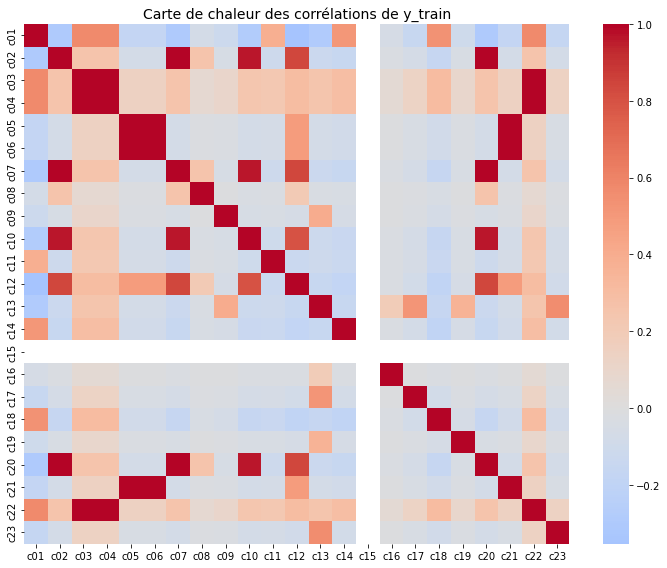

6 composantes principales conservées pour expliquer 95.0% de la variance totale.


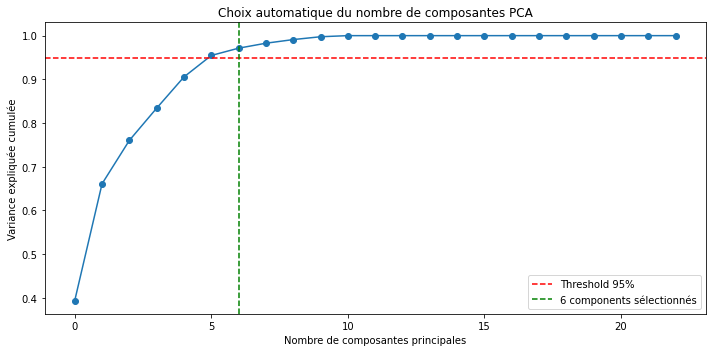

In [8]:
# Réduction de dimension (PCA automatique selon la variance)
# Visualisation : carte de chaleur 
plt.figure(figsize=(10, 8))
sns.heatmap(y.corr(), annot=False, cmap="coolwarm", center=0)
plt.title("Carte de chaleur des corrélations de y_train", fontsize=14)
plt.tight_layout()
plt.savefig("Heatmap.png")
plt.show()

RANDOM_STATE = 42
pca_temp = PCA(random_state=RANDOM_STATE)
pca_temp.fit(y)
cumulative_variance = np.cumsum(pca_temp.explained_variance_ratio_)

# Détermination automatique du nombre de composantes
VARIANCE_THRESHOLD = 0.95
N_COMPONENTS = np.argmax(cumulative_variance >= VARIANCE_THRESHOLD) + 1
print(f"{N_COMPONENTS} composantes principales conservées pour expliquer {VARIANCE_THRESHOLD*100:.1f}% de la variance totale.")

# Variance expliquée cumulée
plt.figure(figsize=(10, 5))
plt.plot(cumulative_variance, marker='o', color='tab:blue')
plt.axhline(VARIANCE_THRESHOLD, color='r', linestyle='--', label=f"Threshold {VARIANCE_THRESHOLD*100:.0f}%")
plt.axvline(N_COMPONENTS, color='g', linestyle='--', label=f"{N_COMPONENTS} components sélectionnés")
plt.xlabel("Nombre de composantes principales")
plt.ylabel("Variance expliquée cumulée")
plt.title("Choix automatique du nombre de composantes PCA")
plt.legend()
plt.tight_layout()
plt.savefig("Variance expliquée cumulée.png")
plt.show()

# Application définitive du PCA
pca = PCA(n_components=N_COMPONENTS, random_state=RANDOM_STATE)
y_reduced = pca.fit_transform(y)

In [9]:
# Weighted RMSE
def weighted_rmse(y_true, y_pred):
    weights = np.where(y_true < 0.5, 1.0, 1.2)
    error_sq = weights * (y_pred - y_true) ** 2
    sample_mean = error_sq.mean(axis=1)
    return np.sqrt(sample_mean.mean())

In [ ]:
# Fonction objectif pour Optuna
XGB_TOTAL_ROUNDS = 300  
RANDOM_STATE = 42  

def objective(trial):
    params = {
        'max_depth': trial.suggest_int('max_depth', 4, 6),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.05),
        'subsample': trial.suggest_float('subsample', 0.7, 0.9),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.7, 0.9),
        'reg_alpha': trial.suggest_float('reg_alpha', 2, 5),
        'reg_lambda': trial.suggest_float('reg_lambda', 5, 12),
        'n_estimators': XGB_TOTAL_ROUNDS,
        'random_state': RANDOM_STATE,
        'n_jobs': -1,
        'tree_method': 'hist'
    }

    # Division train/validation
    X_t, X_v, y_t, y_v = train_test_split(
        X_train_proc, y_reduced, test_size=0.2, random_state=RANDOM_STATE
    )

    # Entraînement du modèle 
    model = XGBRegressor(**params)
    model.fit(X_t, y_t)

    # Prédiction sur le jeu de validation 
    y_val_pred_reduced = model.predict(X_v)
    y_val_pred_full = np.clip(pca.inverse_transform(y_val_pred_reduced), 0.0, 1.0)
    y_val_true_full = np.clip(pca.inverse_transform(y_v), 0.0, 1.0)

    # Score Weighted RMSE 
    score = weighted_rmse(y_val_true_full, y_val_pred_full)
    return score 

In [11]:
# Lancement de l’optimisation bayésienne
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=25, show_progress_bar=True)

print("Best hyperparameters found:")
print(study.best_params)
print(f"Best weighted RMSE: {study.best_value:.6f}")

[I 2025-10-20 23:19:01,355] A new study created in memory with name: no-name-0f19cc3e-3fa5-4186-b4e2-008c8863288b


  0%|          | 0/25 [00:00<?, ?it/s]

[I 2025-10-20 23:19:08,112] Trial 0 finished with value: 0.05770949678499745 and parameters: {'max_depth': 6, 'learning_rate': 0.014275882390385953, 'subsample': 0.7330787702688049, 'colsample_bytree': 0.7855034987864259, 'reg_alpha': 4.769001043003957, 'reg_lambda': 6.0994220545155855}. Best is trial 0 with value: 0.05770949678499745.
[I 2025-10-20 23:19:15,063] Trial 1 finished with value: 0.04573589217212252 and parameters: {'max_depth': 6, 'learning_rate': 0.023581884243477277, 'subsample': 0.7504084979654407, 'colsample_bytree': 0.8357079929855469, 'reg_alpha': 3.8015154680090446, 'reg_lambda': 10.509780530758007}. Best is trial 1 with value: 0.04573589217212252.
[I 2025-10-20 23:19:20,743] Trial 2 finished with value: 0.05486320162278247 and parameters: {'max_depth': 5, 'learning_rate': 0.029064033477647182, 'subsample': 0.8421388197507979, 'colsample_bytree': 0.730842805113848, 'reg_alpha': 2.8384498047397533, 'reg_lambda': 11.662760792251824}. Best is trial 1 with value: 0.0457

In [12]:
# Entraînement du modèle final avec les meilleurs paramètres
best_params = study.best_params
best_params['n_estimators'] = XGB_TOTAL_ROUNDS
best_params['random_state'] = RANDOM_STATE
best_params['n_jobs'] = -1
best_params['tree_method'] = 'hist'

final_model = XGBRegressor(**best_params)
final_model.fit(X_train_proc, y_reduced)

# Évaluation sur le jeu d'entraînement
y_train_pred_reduced = final_model.predict(X_train_proc)
y_train_pred_full = np.clip(pca.inverse_transform(y_train_pred_reduced), 0.0, 1.0)
train_score = weighted_rmse(y.values, y_train_pred_full)
print(f"Final Weighted RMSE on training set: {train_score:.6f}")

Final Weighted RMSE on training set: 0.055733


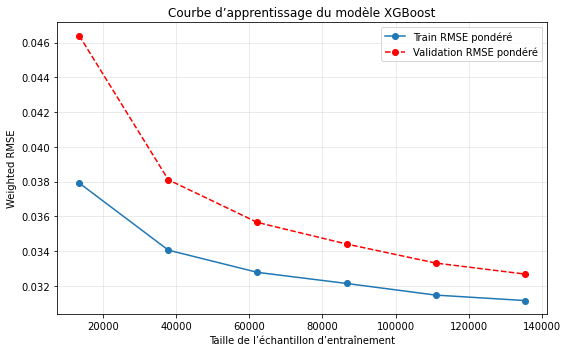

In [13]:
# Fonction de score compatible avec learning_curve 
def weighted_rmse_for_learning_curve(estimator, X, y):
    y_pred_reduced = estimator.predict(X)
    y_pred_full = np.clip(pca.inverse_transform(y_pred_reduced), 0.0, 1.0)
    y_true_full = np.clip(pca.inverse_transform(y), 0.0, 1.0)
    return -weighted_rmse(y_true_full, y_pred_full)

# Calcul de la courbe d’apprentissage
train_sizes, train_scores, val_scores = learning_curve(
    estimator=final_model,
    X=X_train_proc,
    y=y_reduced,
    train_sizes=np.linspace(0.1, 1.0, 6),
    cv=3,
    scoring=weighted_rmse_for_learning_curve,  
    n_jobs=-1
)

# Inversion du signe
train_rmse = -train_scores.mean(axis=1)
val_rmse = -val_scores.mean(axis=1)

# Visualisation 
plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_rmse, 'o-', color='tab:blue', label="Train RMSE pondéré")
plt.plot(train_sizes, val_rmse, 'o--', color='red', label="Validation RMSE pondéré")
plt.xlabel("Taille de l’échantillon d’entraînement")
plt.ylabel("Weighted RMSE")
plt.title("Courbe d’apprentissage du modèle XGBoost")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("learning_curve.png")
plt.show()

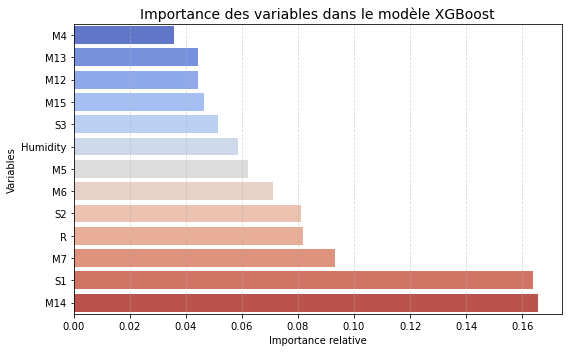

In [14]:
# Importance des variables
importances = final_model.feature_importances_
feat_imp = pd.DataFrame({
    "Variable": X_train.columns,
    "Importance": importances
}).sort_values(by="Importance", ascending=True)

# Visualisation
plt.figure(figsize=(8, 5))
sns.barplot(
    data=feat_imp,
    x="Importance",
    y="Variable",
    palette="coolwarm"
)
plt.title("Importance des variables dans le modèle XGBoost", fontsize=14)
plt.xlabel("Importance relative")
plt.ylabel("Variables")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("feature_importance.png")
plt.show()

In [15]:
# Sauvegarde du fichier de soumission
y_test_pred_reduced = final_model.predict(X_test_proc)
y_test_pred_full = np.clip(pca.inverse_transform(y_test_pred_reduced), 0.0, 1.0)

submission = pd.DataFrame(y_test_pred_full, columns=target_cols)
submission.insert(0, 'ID', pd.read_csv("x_test.csv")['ID'])
submission.to_csv("submission_xgb_pca_autoVariance.csv", index=False)
print("Fichier de soumission sauvegardé : submission_xgb_pca_autoVariance.csv")

Fichier de soumission sauvegardé : submission_xgb_pca_autoVariance.csv
